In [1]:
import json
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import os
import pathlib
import pickle
import sys
from tqdm import tqdm

import torch

from plots import plot_pos, scatter_pos, stemplot, violinplot, add_border_and_ticks
from helpers import optimal_decoder, gather_models, gather_test_data, momentum_plaus, \
                    dict_to_csv, wd_types_to_csvs
from metrics import wasserstein, calc_wds

os.makedirs('pickle', exist_ok=True)
replay_dict_path = 'pickle/replay_unbiased_tanh_plaus.pkl'

## Load models and data

In [2]:
# Hyperparameters
unmask_every = 6 #3
epoch = 15000 
#epoch = 5000 #2500
t_quiescent = 500 #1000 #1000 #250 #100
quiescence = "same" 
lambda_scaling = False

In [3]:
results = pathlib.Path("../results")
noise = 0.0001
config_name = f"noisy_unbiased_unmask_every_{unmask_every}_{noise}"
seed_dirs = [results / "spatial_navigation/tanh" / f \
             for f in os.listdir(results / "spatial_navigation/tanh") if config_name in f]
seed_dirs

[PosixPath('../results/spatial_navigation/tanh/noisy_unbiased_unmask_every_6_0.0001_11'),
 PosixPath('../results/spatial_navigation/tanh/noisy_unbiased_unmask_every_6_0.0001_14'),
 PosixPath('../results/spatial_navigation/tanh/noisy_unbiased_unmask_every_6_0.0001_10'),
 PosixPath('../results/spatial_navigation/tanh/noisy_unbiased_unmask_every_6_0.0001_12'),
 PosixPath('../results/spatial_navigation/tanh/noisy_unbiased_unmask_every_6_0.0001_13')]

In [4]:
# Load models and their test data
models = gather_models(seed_dirs, epoch)
test_obs, test_pos, test_inits = gather_test_data(models)

## Simulating the model with various parameters

In [5]:
tau_a = 50
lambda_v_vals = [1, 0.8, 0.7]
b_a_vals = [0, 0.01, 0.02]

In [6]:
replay = {}
quiescent_inputs = torch.zeros(models[0].task.batch_size, t_quiescent, 2)
for lambda_v in lambda_v_vals:
    for b_a in b_a_vals:
        key = str({'lambda_v': lambda_v, 'tau_a': tau_a, 'b_a': b_a})
        print(key)        
        replay[key] = []
        for (model, init) in zip(models, test_inits):
            pc_act = momentum_plaus(
                model, lambda_v=lambda_v, tau_a=tau_a, b_a=b_a, quiescence=quiescence,
                lambda_scaling=lambda_scaling, x=quiescent_inputs, init_state=init)[1]
            replay[key].append(optimal_decoder(
                model, pc_act, lr=(2e-1 if quiescence=='scaled' else 1e-1),
                verbose=True, iters=51))
        replay[key] = torch.stack(replay[key])

{'lambda_v': 1, 'tau_a': 50, 'b_a': 0}
0 1.998609150177799e-05
5 1.5876365068834275e-05
10 1.387384418194415e-05
15 1.3068444786767941e-05
20 1.2786712431989145e-05
25 1.2669144780375063e-05
30 1.258321208297275e-05
35 1.250456080015283e-05
40 1.2439165402611252e-05
45 1.2391241398290731e-05
50 1.235819945577532e-05
0 2.1068446585559286e-05
5 1.6457968740724027e-05
10 1.465635432396084e-05
15 1.3971172847959679e-05
20 1.3660175682161935e-05
25 1.3473411854647566e-05
30 1.3342398233362474e-05
35 1.3249890798761044e-05
40 1.3185907846491318e-05
45 1.3140280316292774e-05
50 1.310521565756062e-05
0 1.5352052287198603e-05
5 1.2823362339986488e-05
10 1.15359171104501e-05
15 1.0960169674945064e-05
20 1.0711437425925396e-05
25 1.0583859875623602e-05
30 1.0496381946722977e-05
35 1.0427862434880808e-05
40 1.0375451893196441e-05
45 1.0337368621549103e-05
50 1.0310016477887984e-05
0 2.4066477635642514e-05
5 1.9628027075668797e-05
10 1.7315442164544947e-05
15 1.6201745893340558e-05
20 1.57038793986

20 1.671256723057013e-05
25 1.6454119759146124e-05
30 1.630581209610682e-05
35 1.6195874195545912e-05
40 1.610459730727598e-05
45 1.6029081962187774e-05
50 1.5968558727763593e-05
0 1.5678693671361543e-05
5 1.2839574992540292e-05
10 1.1599521712923888e-05
15 1.1063912097597495e-05
20 1.0814158486027736e-05
25 1.0680373634386342e-05
30 1.0596391803119332e-05
35 1.0537713023950346e-05
40 1.0495098649698775e-05
45 1.046399847837165e-05
50 1.0441212907608133e-05
{'lambda_v': 0.9, 'tau_a': 100, 'b_a': 0.2}
0 1.9082855942542665e-05
5 1.6890408005565405e-05
10 1.5776475265738554e-05
15 1.5243345842463896e-05
20 1.4955282495066058e-05
25 1.4764033949177247e-05
30 1.4618320165027399e-05
35 1.450371382816229e-05
40 1.441499716747785e-05
45 1.4347158867167309e-05
50 1.4294751053967047e-05
0 2.5090184863074683e-05
5 1.988304575206712e-05
10 1.761973362590652e-05
15 1.6666206647641957e-05
20 1.6236996088991873e-05
25 1.6011148545658216e-05
30 1.586316830071155e-05
35 1.5750070815556683e-05
40 1.5659

35 1.6620093447272666e-05
40 1.651218371989671e-05
45 1.6422118278569542e-05
50 1.6347008568118326e-05
0 1.6860440155141987e-05
5 1.4938683307264e-05
10 1.3775303159491159e-05
15 1.3115070942149032e-05
20 1.2747466826112941e-05
25 1.2533803783298936e-05
30 1.2397185855661519e-05
35 1.2300966773182154e-05
40 1.2229142157593742e-05
45 1.2174305993539747e-05
50 1.213207815453643e-05
0 2.622770807647612e-05
5 2.2429181626648642e-05
10 2.031393705692608e-05
15 1.925843025674112e-05
20 1.8732151147560216e-05
25 1.8428194380248897e-05
30 1.8210685084341094e-05
35 1.803312261472456e-05
40 1.788412373571191e-05
45 1.776118551788386e-05
50 1.7661592210060917e-05
0 1.535941191832535e-05
5 1.3706052413908765e-05
10 1.2664425412367564e-05
15 1.2030987818434369e-05
20 1.1656706192297861e-05
25 1.1438648471084889e-05
30 1.1309685760352295e-05
35 1.1229332812945358e-05
40 1.1175196050317027e-05
45 1.1135881322843488e-05
50 1.1105918929388281e-05
{'lambda_v': 0.7, 'tau_a': 100, 'b_a': 0}
0 2.4778415536

In [7]:
# save repays
with open(replay_dict_path, 'wb') as file:
    pickle.dump(replay, file)

In [8]:
# load replays
with open(replay_dict_path, 'rb') as file:
    replay = pickle.load(file)

In [9]:
list(replay.values())[0].shape # seeds, N, T, 2

torch.Size([5, 200, 500, 2])

## Decoded outputs

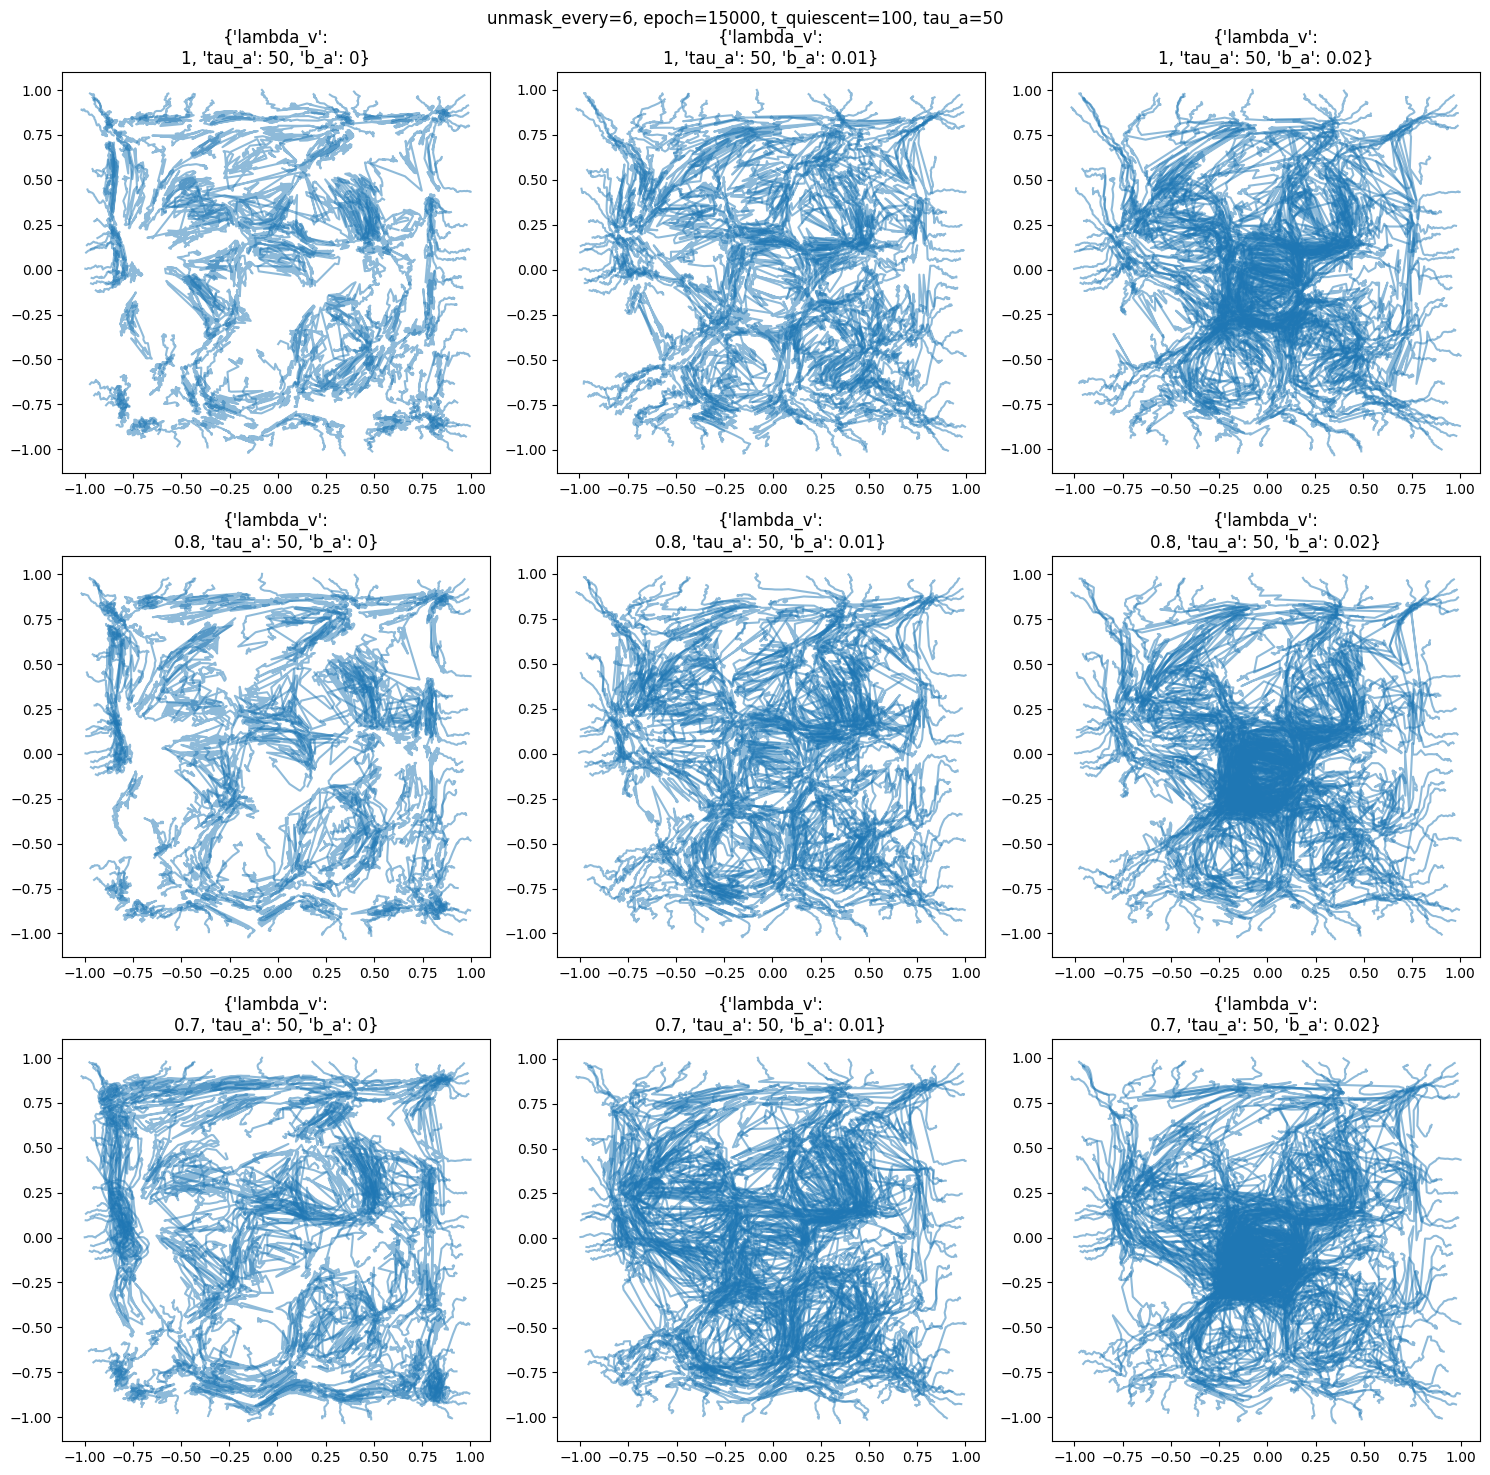

In [10]:
idx = 0
fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(15,15))
axs = axs.flatten()
for i,(k,v) in enumerate(replay.items()):
    plot_pos(axs[i], v[idx,:,:100], title = k[:k.index(' ')] + '\n' + k[k.index(' ')+1:])
fig.suptitle(f'{unmask_every=}, {epoch=}, t_quiescent=100, {tau_a=}')
fig.tight_layout()

## Wasserstein distance

In [11]:
wds = calc_wds(replay, test_pos)

100%|█████████████████████████████████████████████| 9/9 [00:12<00:00,  1.44s/it]


In [12]:
dict_to_csv(wds, 'b_a', path='../csv/plaus_tanh_wds_unbiased.csv')

,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02
0,1.0,50,0.118516,0.162956,0.239311
1,0.8,50,0.118523,0.169798,0.263097
2,0.7,50,0.114484,0.181586,0.286591


## Distances traveled

In [13]:
def calculate_path_lens(x):
    assert x.ndim == 3 and x.shape[-1] == 2
    # differentiate along T (dim 1),
    # calculate dx (square sum sqrt),
    # sum along T (now dim -1)
    return x.diff(dim=1).square().sum(-1).sqrt().sum(-1)

dist_avg = {}
for k, x_hat in replay.items():
    # combine seed and sample dim. x_hat shape = (-1, timesteps, 2)
    x_hat = x_hat.flatten(0,1)
    path_lens = calculate_path_lens(x_hat)
    dist_avg[k] = path_lens.mean().item()

In [14]:
print(calculate_path_lens(test_pos.flatten(0,1)).mean().item())
dict_to_csv(dist_avg, col_param='b_a', path='../csv/exploration/plaus_tanh_exploration_distance_unbiased.csv')

1.9500248432159424


,lambda_v,tau_a,b_a=0.0,b_a=0.01,b_a=0.02
0,1.0,50,6.166390,14.216472,14.806088
1,0.8,50,6.226143,14.803353,15.558911
2,0.7,50,40.379250,47.063046,46.581360
